<a href="https://colab.research.google.com/github/shivamkumar359/03-rd-SEM--ASSIGNMENTS/blob/main/PDS_W_10_DEN_Q2_ASSIGNMENT_2_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# TASK 2: SEARCH AND HASHING OPERATIONS
# ============================================================

import csv
import zipfile
import os
import matplotlib.pyplot as plt

In [3]:
# ============================================================
# 1. LINEAR SEARCH
# ============================================================

def linear_search(arr, target):
    comparisons = 0

    for i in range(len(arr)):
        comparisons += 1

        if arr[i] == target:
            return i, comparisons

    return -1, comparisons


In [5]:
# ============================================================
# 2. BINARY SEARCH
# ============================================================

def binary_search(arr, target):
    low = 0
    high = len(arr) - 1
    comparisons = 0
    steps = []

    while low <= high:

        mid = (low + high) // 2
        comparisons += 1

        steps.append({
            "comparison": comparisons,
            "low": low,
            "high": high,
            "mid": mid,
            "value": arr[mid]
        })

        if arr[mid] == target:
            return mid, comparisons, steps

        elif arr[mid] < target:
            low = mid + 1

        else:
            high = mid - 1

    return -1, comparisons, steps

In [6]:
# ============================================================
# 3. HASH TABLE USING CHAINING
# ============================================================

class HashTable:

    def __init__(self, size=7):
        self.size = size
        self.table = [[] for _ in range(size)]
        self.collision_messages = []

    def hash_function(self, key):
        return key % self.size

    def insert(self, key):

        index = self.hash_function(key)

        if self.table[index]:

            message = (
                f"Collision: Key {key} maps to index {index}. "
                f"Existing keys: {self.table[index]}. "
                f"Applying chaining."
            )

            self.collision_messages.append(message)
            print(message)

        self.table[index].append(key)

        return index

    def search(self, key):

        index = self.hash_function(key)

        if key in self.table[index]:
            return index

        return -1

    def display(self):

        for i in range(self.size):
            print(f"Index {i}: {self.table[i]}")

In [8]:
# ============================================================
# 4. INPUT DATASET
# ============================================================

original_array = [5, 3, 8, 1, 2]
sorted_array = sorted(original_array)

print("=" * 55)
print("TASK 2: SEARCH AND HASHING OPERATIONS")
print("=" * 55)

print("Original Array:", original_array)
print("Sorted Array:", sorted_array)

TASK 2: SEARCH AND HASHING OPERATIONS
Original Array: [5, 3, 8, 1, 2]
Sorted Array: [1, 2, 3, 5, 8]



LINEAR SEARCH
----------------------------------------
Target: 5
Found at Index: 0
Comparisons: 1

Searching for Target 7
Result: Not Found
Comparisons: 5

BINARY SEARCH
----------------------------------------
Comparison 1: low=0, high=4, mid=2, value=3
Comparison 2: low=3, high=4, mid=3, value=5

Target: 5
Found at Index: 3
Total Comparisons: 2
Binary Search: PASSED

Searching for Target 7
Result: Not Found
Comparisons: 3

HASH TABLE OPERATIONS
----------------------------------------
Collision: Key 19 maps to index 5. Existing keys: [12]. Applying chaining.

Final Hash Table:
Index 0: []
Index 1: []
Index 2: []
Index 3: []
Index 4: [25]
Index 5: [12, 19]
Index 6: []

CSV FILE CREATED: hash_results.csv


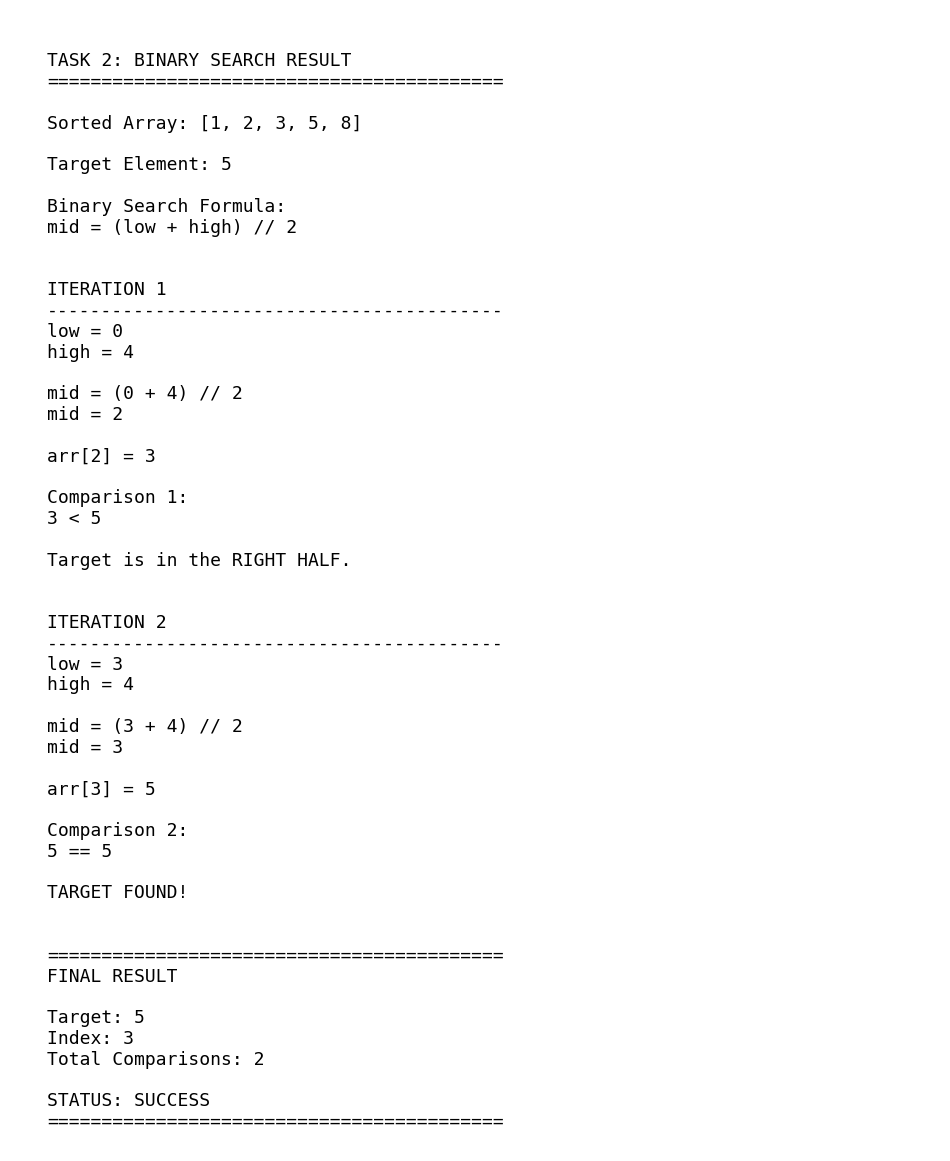

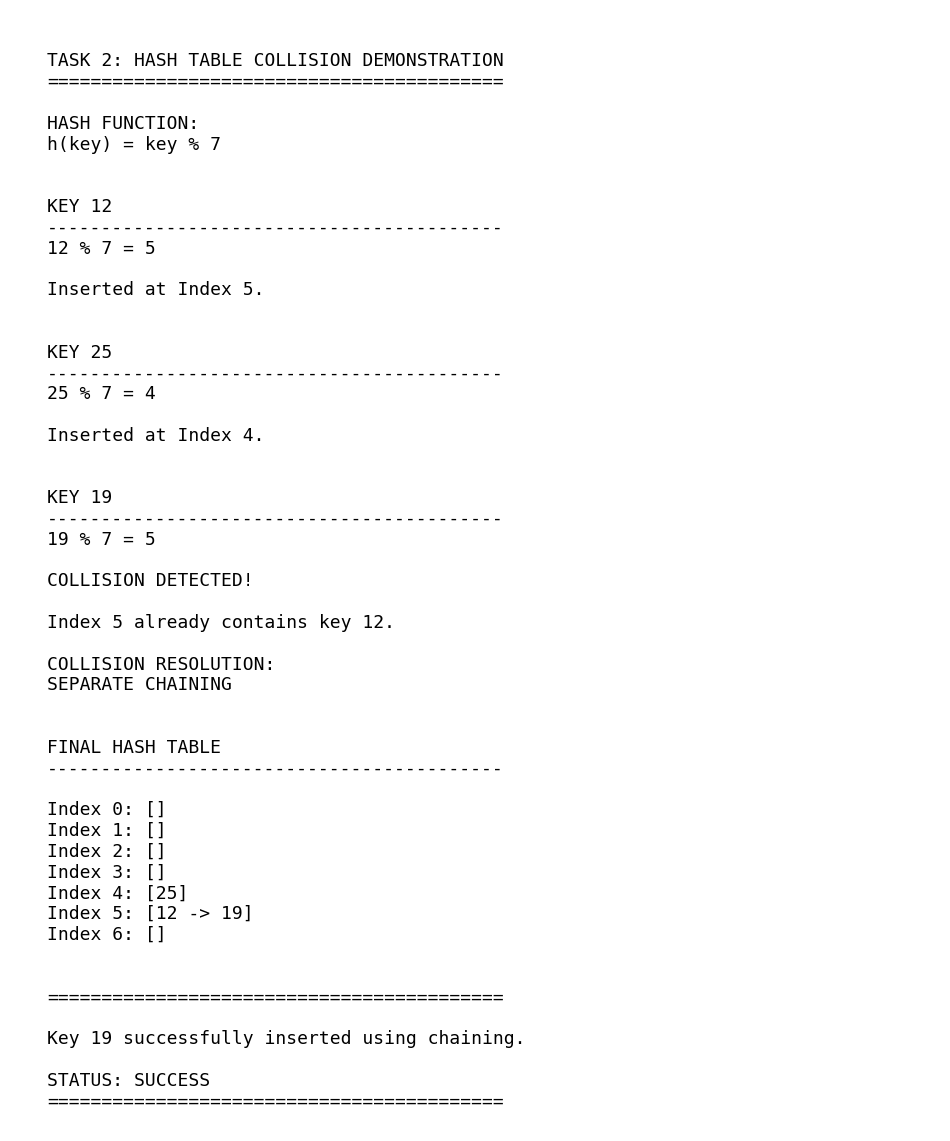

In [10]:

# ============================================================
# 5. LINEAR SEARCH DEMONSTRATION
# ============================================================

print("\nLINEAR SEARCH")
print("-" * 40)

index, comparisons = linear_search(original_array, 5)

print("Target: 5")
print("Found at Index:", index)
print("Comparisons:", comparisons)

# Search for missing target 7

index, comparisons = linear_search(original_array, 7)

print("\nSearching for Target 7")
print("Result:", "Not Found" if index == -1 else index)
print("Comparisons:", comparisons)


# ============================================================
# 6. BINARY SEARCH DEMONSTRATION
# ============================================================

print("\nBINARY SEARCH")
print("-" * 40)

target = 5

index, comparisons, steps = binary_search(
    sorted_array, target
)

for step in steps:
    print(
        f"Comparison {step['comparison']}: "
        f"low={step['low']}, "
        f"high={step['high']}, "
        f"mid={step['mid']}, "
        f"value={step['value']}"
    )

print("\nTarget:", target)
print("Found at Index:", index)
print("Total Comparisons:", comparisons)

assert index == 3
assert comparisons == 2

print("Binary Search: PASSED")


# ============================================================
# 7. BINARY SEARCH FOR TARGET 7
# ============================================================

missing_index, missing_comparisons, missing_steps = (
    binary_search(sorted_array, 7)
)

print("\nSearching for Target 7")
print("Result:", "Not Found" if missing_index == -1 else missing_index)
print("Comparisons:", missing_comparisons)


# ============================================================
# 8. HASHING DEMONSTRATION
# ============================================================

print("\nHASH TABLE OPERATIONS")
print("-" * 40)

hash_table = HashTable(size=7)

keys = [12, 25, 19]

hash_results = []

for key in keys:

    index = hash_table.insert(key)

    hash_results.append([
        key,
        f"{key} % 7",
        index
    ])

print("\nFinal Hash Table:")
hash_table.display()


# ============================================================
# 9. CREATE hash_results.csv
# ============================================================

with open("hash_results.csv", "w", newline="") as file:

    writer = csv.writer(file)

    writer.writerow([
        "Key",
        "Hash Function",
        "Hash Index"
    ])

    writer.writerows(hash_results)

print("\nCSV FILE CREATED: hash_results.csv")


# ============================================================
# 10. GENERATE BINARY SEARCH SCREENSHOT
# ============================================================

fig, ax = plt.subplots(figsize=(12, 7))

ax.axis("off")

binary_report = """
TASK 2: BINARY SEARCH RESULT
==========================================

Sorted Array: [1, 2, 3, 5, 8]

Target Element: 5

Binary Search Formula:
mid = (low + high) // 2


ITERATION 1
------------------------------------------
low = 0
high = 4

mid = (0 + 4) // 2
mid = 2

arr[2] = 3

Comparison 1:
3 < 5

Target is in the RIGHT HALF.


ITERATION 2
------------------------------------------
low = 3
high = 4

mid = (3 + 4) // 2
mid = 3

arr[3] = 5

Comparison 2:
5 == 5

TARGET FOUND!


==========================================
FINAL RESULT

Target: 5
Index: 3
Total Comparisons: 2

STATUS: SUCCESS
==========================================
"""

ax.text(
    0.04, 0.96,
    binary_report,
    fontsize=13,
    family="monospace",
    verticalalignment="top"
)

plt.savefig(
    "binary_search_output.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 11. GENERATE HASH COLLISION SCREENSHOT
# ============================================================

fig, ax = plt.subplots(figsize=(12, 7))

ax.axis("off")

collision_report = """
TASK 2: HASH TABLE COLLISION DEMONSTRATION
==========================================

HASH FUNCTION:
h(key) = key % 7


KEY 12
------------------------------------------
12 % 7 = 5

Inserted at Index 5.


KEY 25
------------------------------------------
25 % 7 = 4

Inserted at Index 4.


KEY 19
------------------------------------------
19 % 7 = 5

COLLISION DETECTED!

Index 5 already contains key 12.

COLLISION RESOLUTION:
SEPARATE CHAINING


FINAL HASH TABLE
------------------------------------------

Index 0: []
Index 1: []
Index 2: []
Index 3: []
Index 4: [25]
Index 5: [12 -> 19]
Index 6: []


==========================================

Key 19 successfully inserted using chaining.

STATUS: SUCCESS
==========================================
"""

ax.text(
    0.04, 0.96,
    collision_report,
    fontsize=13,
    family="monospace",
    verticalalignment="top"
)

plt.savefig(
    "hash_collision_output.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 12. CREATE search_hashing.py
# ============================================================

python_code = '''
# TASK 2: SEARCH AND HASHING OPERATIONS

def linear_search(arr, target):

    comparisons = 0

    for i in range(len(arr)):

        comparisons += 1

        if arr[i] == target:
            return i, comparisons

    return -1, comparisons


def binary_search(arr, target):

    low = 0
    high = len(arr) - 1
    compariso

        else:
            high = mid - 1

    return -1, comparisons


class HashTable:

    def __init__(self, size=7):
        self.size = size
        self.table = [[] for _ in range(size)]

    def hash_function(self, key):
        return key % self.size

    def insert(self, key):

        index = self.hash_function(key)

        if self.table[index]:
            print("Collision detected at index", index)
            print("Using separate chaining.")

        self.table[index].append(key)

        return index

    def search(self, key):

        index = self.hash_function(key)

        if key in self.table[index]:
            return index

        return -1

    def display(self):

        for i in range(self.size):
            print(f"Index {i}: {self.table[i]}")


if __name__ == "__main__":

    data = [5, 3, 8, 1, 2]
    sorted_data = sorted(data)

    print("Original Array:", data)
    print("Sorted Array:", sorted_data)

    print("\\nLinear Search:", linear_search(data, 5))

    print("\\nBinary Search:", binary_search(sorted_data, 5))

    print("\\nSearch for 7:", binary_search(sorted_data, 7))

    ht = HashTable(7)

    for key in [12, 25, 19]:
        print("Key:", key, "Index:", ht.insert(key))

    print("\\nFinal Hash Table:")
    ht.display()
'''

with open("search_hashing.py", "w") as file:
    file.write(python_code)



In [11]:

# ============================================================
# 13. VALIDATE ALL SUCCESS CRITERIA
# ============================================================

assert linear_search(original_array, 7)[0] == -1

assert binary_search(sorted_array, 5)[0] == 3

assert binary_search(sorted_array, 5)[1] == 2

assert binary_search(sorted_array, 7)[0] == -1

assert hash_table.hash_function(12) == 5

assert hash_table.hash_function(25) == 4

assert hash_table.hash_function(19) == 5

assert hash_table.table[5] == [12, 19]

assert hash_table.table[4] == [25]

print("\n" + "=" * 55)
print("ALL SUCCESS CRITERIA VERIFIED")
print("=" * 55)

print("Linear Search: PASSED")
print("Binary Search: PASSED")
print("Exactly Two Comparisons: PASSED")
print("Target 7 Not Found: PASSED")
print("Modulo 7 Hash Function: PASSED")
print("Collision Handling: PASSED")


# ============================================================
# 14. CREATE ZIP FILE
# ============================================================

deliverables = [
    "search_hashing.py",
    "hash_results.csv",
    "binary_search_output.png",
    "hash_collision_output.png"
]

zip_filename = "TASK2_Search_Hashing_Deliverables.zip"

with zipfile.ZipFile(
    zip_filename,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for filename in deliverables:
        zip_file.write(filename)

print("\nGENERATED DELIVERABLES")
print("=" * 55)

for filename in deliverables:
    print("[SUCCESS]", filename)

print("[SUCCESS]", zip_filename)

print("\nTASK 2 COMPLETED SUCCESSFULLY!")


ALL SUCCESS CRITERIA VERIFIED
Linear Search: PASSED
Binary Search: PASSED
Exactly Two Comparisons: PASSED
Target 7 Not Found: PASSED
Modulo 7 Hash Function: PASSED
Collision Handling: PASSED

GENERATED DELIVERABLES
[SUCCESS] search_hashing.py
[SUCCESS] hash_results.csv
[SUCCESS] binary_search_output.png
[SUCCESS] hash_collision_output.png
[SUCCESS] TASK2_Search_Hashing_Deliverables.zip

TASK 2 COMPLETED SUCCESSFULLY!
